In [1]:
import os, json, time, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

REPO_URL = "https://github.com/Mugdha-Naik/deepfake-detector-project.git"
REPO_DIR = "/kaggle/working/repo"
if not os.path.exists(REPO_DIR):
    os.system(f"git clone {REPO_URL} {REPO_DIR}")
INPUT_ROOT = "/kaggle/input"
OUT = "/kaggle/working/p2_8"
os.makedirs(OUT, exist_ok=True)

SEED = 2026
K_IOU = 20            # top-20% cells (20 of 100) for the overlap measure
FLOOR_REPS = 5        # random partners per face for the floors
N_BOOT = 1000         # video bootstrap resamples (paired stability)
N_BOOT_DIST = 500     # video bootstrap resamples (distribution comparisons)
HALF_SPLITS = 300     # split-half repetitions for the distribution reference
MIN_FACES, MIN_VIDEOS = 30, 10
GRID = 10

def find_one(name, roots):
    for root in roots:
        matches = [os.path.join(d, name) for d, _, fs in os.walk(root) if name in fs]
        if len(matches) == 1:
            return matches[0]
        if len(matches) > 1:
            raise RuntimeError(f"{name}: {len(matches)} copies under {root}. Attach only one:\n" + "\n".join(matches))
    raise FileNotFoundError(f"{name} not found under {roots}")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()
print("setup OK")

Cloning into '/kaggle/working/repo'...


setup OK


In [2]:
# ============================================================
# LOAD AND CHECK INPUTS (hashes, thresholds, ids)
# ============================================================
ROOTS = [INPUT_ROOT, REPO_DIR]
manifest_csv = find_one("faces_manifest.csv", ROOTS)
g_meta = json.load(open(find_one("gradcam_meta.json", ROOTS)))
eval_meta = json.load(open(find_one("eval_meta.json", ROOTS)))
MANIFEST_SHA = g_meta["manifest_sha256"]
assert sha256(manifest_csv) == MANIFEST_SHA, "faces_manifest.csv is not the manifest the Step 2.6 maps were made with"
assert g_meta["model_sha256"] == eval_meta["model_sha256"], "Step 2.5 and Step 2.6 used different checkpoints"
THRESHOLD = float(g_meta["threshold"])
assert abs(THRESHOLD - 0.2217) < 5e-4 and abs(eval_meta["threshold"] - THRESHOLD) < 1e-9, "threshold is not the frozen 0.2217"

cams, pred25 = {}, {}
for k in "ABCD":
    z = np.load(find_one(f"cams_{k}.npz", [INPUT_ROOT]), allow_pickle=True)
    ids = np.array([str(i) for i in z["face_id"]])
    cams[k] = {"ids": ids, "cam": z["cam"].astype(np.float64), "target": z["target"].astype(int),
               "idx": {f: i for i, f in enumerate(ids)}}
    assert cams[k]["cam"].shape[1:] == (GRID, GRID), f"{k}: maps are not 10x10"
    pr = pd.read_csv(find_one(f"predictions_{k}.csv", ROOTS)); pr["face_id"] = pr["face_id"].astype(str)
    assert set(pr["face_id"]) == set(ids), f"{k}: Step 2.5 predictions and Step 2.6 maps cover different faces"
    pred25[k] = pr.set_index("face_id")
    print(f"{k}: {len(ids)} maps, {pred25[k]['video_id'].nunique()} videos")

# Twin pairing comes from pair_id in the Step 2.5 predictions of B and D (written there from the B/D manifests).
pairs_df = {}
for clean, comp in (("A", "B"), ("C", "D")):
    pr = pred25[comp]
    assert "pair_id" in pr.columns, f"predictions_{comp}.csv has no pair_id column; attach faces_manifest_{comp}.csv instead"
    m = pd.DataFrame({"face_id": pr.index.astype(str), "pair_id": pr["pair_id"].astype(str).to_numpy()})
    assert m["pair_id"].is_unique and m["face_id"].is_unique, f"{comp}: pairing is not one-to-one"
    assert set(m["pair_id"]) == set(cams[clean]["ids"]) and set(m["face_id"]) == set(cams[comp]["ids"]), f"{comp}: pair_id does not match the faces"
    try:                                                   # optional cross-check if the B/D manifest is attached
        mm = pd.read_csv(find_one(f"faces_manifest_{comp}.csv", ROOTS)); mm["face_id"] = mm["face_id"].astype(str); mm["pair_id"] = mm["pair_id"].astype(str)
        assert dict(zip(mm["face_id"], mm["pair_id"])) == dict(zip(m["face_id"], m["pair_id"])), f"{comp}: manifest pair_id differs from the predictions file"
        print(f"{comp}: pair_id cross-checked against faces_manifest_{comp}.csv")
    except FileNotFoundError:
        print(f"{comp}: pairing taken from predictions_{comp}.csv (B/D manifest not attached, that is fine)")
    pairs_df[(clean, comp)] = m.reset_index(drop=True)
print("inputs OK | threshold", THRESHOLD, "| manifest", MANIFEST_SHA[:8])

A: 5883 maps, 198 videos
B: 5883 maps, 198 videos
C: 8763 maps, 300 videos
D: 8763 maps, 300 videos
B: pairing taken from predictions_B.csv (B/D manifest not attached, that is fine)
D: pairing taken from predictions_D.csv (B/D manifest not attached, that is fine)
inputs OK | threshold 0.22168749570846558 | manifest 80eae250


In [3]:
# ============================================================
# SIMILARITY, DESCRIPTOR AND BOOTSTRAP FUNCTIONS
# ============================================================
def flat(X): return np.asarray(X, dtype=np.float64).reshape(len(X), -1)

def cos_rows(a, b):
    na, nb = np.linalg.norm(a, axis=1), np.linalg.norm(b, axis=1)
    return (a * b).sum(1) / np.where((na < 1e-9) | (nb < 1e-9), np.nan, na * nb)

def pearson_rows(a, b):
    a0, b0 = a - a.mean(1, keepdims=True), b - b.mean(1, keepdims=True)
    sa, sb = np.sqrt((a0 ** 2).sum(1)), np.sqrt((b0 ** 2).sum(1))
    return (a0 * b0).sum(1) / np.where((sa < 1e-9) | (sb < 1e-9), np.nan, sa * sb)

def top_mask(X, n):
    order = np.argsort(-X, axis=1, kind="stable")[:, :n]
    M = np.zeros(X.shape, dtype=bool); np.put_along_axis(M, order, True, axis=1); return M

def iou_rows(a, b, n=K_IOU):
    ma, mb = top_mask(a, n), top_mask(b, n)
    iou = (ma & mb).sum(1) / (ma | mb).sum(1).astype(float)
    empty = (a.max(1) <= 1e-9) | (b.max(1) <= 1e-9)
    iou[empty] = np.nan; return iou

def cam_stats(c):
    """c: (N,10,10) normalised maps. Same definitions as Step 2.6."""
    c = np.asarray(c, dtype=np.float64).reshape(-1, GRID, GRID); N = len(c)
    s = c.reshape(N, -1).sum(1); ok = s > 1e-12
    p = np.zeros_like(c); p[ok] = c[ok] / s[ok, None, None]
    ent = -(p * np.log(p + 1e-12)).reshape(N, -1).sum(1) / np.log(100)
    yy, xx = np.mgrid[0:GRID, 0:GRID]; yy = (yy + 0.5) / GRID; xx = (xx + 0.5) / GRID
    out = pd.DataFrame({"entropy": ent, "com_y": (p * yy).reshape(N, -1).sum(1), "com_x": (p * xx).reshape(N, -1).sum(1),
                        "central_share": p[:, 2:8, 2:8].reshape(N, -1).sum(1), "peak_share": p.reshape(N, -1).max(1)})
    out.loc[~ok, :] = np.nan; return out

def boot_mean_ci(df, col, n_boot=N_BOOT, seed=SEED):
    d = df.dropna(subset=[col])
    if len(d) == 0: return (np.nan, np.nan, np.nan)
    g = d.groupby("video_id")[col].agg(["sum", "count"]).to_numpy(float)
    if len(g) < 2: return (float(d[col].mean()), np.nan, np.nan)
    rng = np.random.default_rng(seed); idx = rng.integers(0, len(g), size=(n_boot, len(g)))
    means = g[idx, 0].sum(1) / g[idx, 1].sum(1)
    return float(g[:, 0].sum() / g[:, 1].sum()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))
print("functions ready")

functions ready


In [4]:
# ============================================================
# PAIRED STABILITY: A->B and C->D (same face, same box; only compression differs)
# ============================================================
CLS = {1: "FAKE", -1: "REAL"}
paired, Xs = {}, {}
for clean, comp in (("A", "B"), ("C", "D")):
    pdf = pairs_df[(clean, comp)]
    ic = np.array([cams[clean]["idx"][f] for f in pdf["pair_id"]]); iz = np.array([cams[comp]["idx"][f] for f in pdf["face_id"]])
    Xc, Xz = flat(cams[clean]["cam"][ic]), flat(cams[comp]["cam"][iz])
    pc, pz = pred25[clean].loc[pdf["pair_id"]], pred25[comp].loc[pdf["face_id"]]
    assert (pc["video_id"].to_numpy() == pz["video_id"].to_numpy()).all(), f"{comp}: a twin is in a different video"
    sc, sz = cam_stats(Xc), cam_stats(Xz)
    tc, tz = cams[clean]["target"][ic], cams[comp]["target"][iz]
    df = pd.DataFrame({"pair_id": pdf["pair_id"], "face_id": pdf["face_id"], "video_id": pz["video_id"].to_numpy(),
                       "cos": cos_rows(Xc, Xz), "pearson": pearson_rows(Xc, Xz), "iou20": iou_rows(Xc, Xz),
                       "com_shift": np.hypot(sc["com_y"] - sz["com_y"], sc["com_x"] - sz["com_x"]),
                       "entropy_clean": sc["entropy"], "entropy_comp": sz["entropy"],
                       "target_clean": tc, "target_comp": tz, "flip_target": tc != tz,
                       "direction": [f"{CLS[a]}->{CLS[b]}" for a, b in zip(tc, tz)],
                       "pred_clean_2_5": pc["pred"].to_numpy(), "pred_comp_2_5": pz["pred"].to_numpy(),
                       "outcome_clean": pc["outcome"].to_numpy(), "outcome_comp": pz["outcome"].to_numpy()})
    df["flip_2_5"] = df["pred_clean_2_5"] != df["pred_comp_2_5"]
    paired[(clean, comp)] = df; Xs[(clean, comp)] = (Xc, Xz, df["video_id"].to_numpy())
    print(f"{clean}->{comp}: {len(df)} pairs | mean cosine {df['cos'].mean():.3f} | explained-class flips {df['flip_target'].mean() * 100:.2f}% | "
          f"Step 2.5 prediction flips {df['flip_2_5'].mean() * 100:.2f}% | empty-map pairs {df['cos'].isna().mean() * 100:.2f}%")

A->B: 5883 pairs | mean cosine 0.701 | explained-class flips 41.25% | Step 2.5 prediction flips 41.34% | empty-map pairs 0.00%
C->D: 8763 pairs | mean cosine 0.643 | explained-class flips 53.54% | Step 2.5 prediction flips 53.47% | empty-map pairs 0.01%


In [5]:
# ============================================================
# RANDOM-PAIR FLOORS (unrelated faces = different videos)
# ============================================================
def partners(vid_a, vid_b, rng, reps):
    n, m = len(vid_a), len(vid_b); out = []
    for _ in range(reps):
        j = rng.integers(0, m, n)
        for _ in range(100):
            bad = vid_a == vid_b[j]
            if not bad.any(): break
            j[bad] = rng.integers(0, m, int(bad.sum()))
        assert not (vid_a == vid_b[j]).any(), "could not find partners from other videos"
        out.append(j)
    return out

def floor_metrics(XA, vidA, XB, vidB, rng):
    cs, ps, ious = [], [], []
    for j in partners(vidA, vidB, rng, FLOOR_REPS):
        cs.append(cos_rows(XA, XB[j])); ps.append(pearson_rows(XA, XB[j])); ious.append(iou_rows(XA, XB[j]))
    return {"cos": np.concatenate(cs), "pearson": np.concatenate(ps), "iou20": np.concatenate(ious)}

rng = np.random.default_rng(SEED)
floors, rows, long_rows = {}, [], []
for (clean, comp), (Xc, Xz, vid) in Xs.items():
    pair = f"{clean}->{comp}"
    floors[pair] = {"within_clean": floor_metrics(Xc, vid, Xc, vid, rng),
                    "within_comp": floor_metrics(Xz, vid, Xz, vid, rng),
                    "cross": floor_metrics(Xc, vid, Xz, vid, rng)}
    for ftype, d in floors[pair].items():
        for met, arr in d.items():
            a = arr[~np.isnan(arr)]
            rows.append({"pair": pair, "floor_type": ftype + (" (PRIMARY)" if ftype == "within_clean" else ""), "metric": met, "n_samples": len(a),
                         "mean": a.mean(), "p5": np.percentile(a, 5), "p50": np.percentile(a, 50), "p95": np.percentile(a, 95)})
        long_rows.append(pd.DataFrame({"pair": pair, "floor_type": ftype, "cos": d["cos"], "pearson": d["pearson"], "iou20": d["iou20"]}))
floor_table = pd.DataFrame(rows); floor_table.to_csv(os.path.join(OUT, "stability_floor.csv"), index=False)
pd.concat(long_rows, ignore_index=True).to_csv(os.path.join(OUT, "stability_floor_samples.csv"), index=False)
print(floor_table.round(3).to_string(index=False))

FLOOR = {}
for pair in floors:
    p95 = {ft: float(np.nanpercentile(floors[pair][ft]["cos"], 95)) for ft in floors[pair]}
    FLOOR[pair] = {"primary_p95": p95["within_clean"], "conservative_p95": max(p95.values()), "primary_mean": float(np.nanmean(floors[pair]["within_clean"]["cos"]))}
for (clean, comp), df in paired.items():
    pair = f"{clean}->{comp}"
    df["above_floor_primary"] = np.where(df["cos"].isna(), np.nan, (df["cos"] > FLOOR[pair]["primary_p95"]).astype(float))
    df["above_floor_conservative"] = np.where(df["cos"].isna(), np.nan, (df["cos"] > FLOOR[pair]["conservative_p95"]).astype(float))
    df.to_csv(os.path.join(OUT, f"stability_{clean}_{comp}.csv"), index=False)
print("\nFloor p95 (cosine):", {p: {k: round(v, 3) for k, v in d.items()} for p, d in FLOOR.items()})

pair             floor_type  metric  n_samples  mean     p5   p50   p95
A->B within_clean (PRIMARY)     cos      29415 0.673  0.232 0.726 0.938
A->B within_clean (PRIMARY) pearson      29415 0.539 -0.076 0.611 0.913
A->B within_clean (PRIMARY)   iou20      29415 0.408  0.081 0.429 0.739
A->B            within_comp     cos      29415 0.668  0.246 0.718 0.930
A->B            within_comp pearson      29415 0.490 -0.100 0.550 0.889
A->B            within_comp   iou20      29415 0.351  0.053 0.333 0.667
A->B                  cross     cos      29415 0.656  0.232 0.702 0.927
A->B                  cross pearson      29415 0.497 -0.090 0.556 0.891
A->B                  cross   iou20      29415 0.368  0.053 0.379 0.667
C->D within_clean (PRIMARY)     cos      43815 0.617  0.166 0.659 0.928
C->D within_clean (PRIMARY) pearson      43815 0.487 -0.093 0.536 0.903
C->D within_clean (PRIMARY)   iou20      43815 0.379  0.081 0.379 0.739
C->D            within_comp     cos      43804 0.573  0.119 0.61

In [6]:
# ============================================================
# SUMMARIES: paired scores next to the floor, split by prediction-flip status
# ============================================================
def group_row(df, pair, group):
    row = {"pair": pair, "group": group, "n_pairs": len(df), "n_videos": df["video_id"].nunique()}
    for col, lab in (("cos", "cosine"), ("pearson", "pearson"), ("iou20", "iou_top20"), ("com_shift", "com_shift")):
        m, lo, hi = boot_mean_ci(df, col); row.update({f"{lab}_mean": m, f"{lab}_ci_lo": lo, f"{lab}_ci_hi": hi})
    v = df.dropna(subset=["cos"])
    row["floor_mean_primary"] = FLOOR[pair]["primary_mean"]; row["floor_p95_primary"] = FLOOR[pair]["primary_p95"]; row["floor_p95_conservative"] = FLOOR[pair]["conservative_p95"]
    row["share_above_floor_primary"] = float(v["above_floor_primary"].astype(float).mean()) if len(v) else np.nan
    row["share_above_floor_conservative"] = float(v["above_floor_conservative"].astype(float).mean()) if len(v) else np.nan
    row["descriptive_only"] = len(df) < MIN_FACES or df["video_id"].nunique() < MIN_VIDEOS
    return row

rows, eff = [], []
for (clean, comp), df in paired.items():
    pair = f"{clean}->{comp}"
    rows.append(group_row(df, pair, "ALL"))
    for name, mask in (("class unchanged", ~df["flip_target"]), ("class flipped", df["flip_target"])):
        if mask.any(): rows.append(group_row(df[mask], pair, name))
    for dr in sorted(df["direction"].unique()):
        rows.append(group_row(df[df["direction"] == dr], pair, f"direction {dr}"))
    for o in ("TP", "FP", "FN", "TN"):
        sub = df[df["outcome_clean"] == o]
        if len(sub): rows.append(group_row(sub, pair, f"clean outcome {o}"))
    u, f_ = df.loc[~df["flip_target"], "cos"].dropna(), df.loc[df["flip_target"], "cos"].dropna()
    if len(u) and len(f_):
        U = stats.mannwhitneyu(u, f_, alternative="two-sided").statistic
        eff.append({"pair": pair, "n_unchanged": len(u), "n_flipped": len(f_), "mean_cos_unchanged": u.mean(), "mean_cos_flipped": f_.mean(),
                    "prob_unchanged_more_similar": float(U / (len(u) * len(f_))),
                    "note": "effect size only; faces within a video are not independent, so no p-value is reported"})
stab_summary = pd.DataFrame(rows); stab_summary.to_csv(os.path.join(OUT, "stability_summary.csv"), index=False)
flip_effect = pd.DataFrame(eff); flip_effect.to_csv(os.path.join(OUT, "stability_flip_effect.csv"), index=False)
cols = ["pair", "group", "n_pairs", "n_videos", "cosine_mean", "cosine_ci_lo", "cosine_ci_hi", "iou_top20_mean", "floor_p95_primary", "share_above_floor_primary", "descriptive_only"]
print(stab_summary[cols].round(3).to_string(index=False))
print("\n", flip_effect.round(3).to_string(index=False))

pair                group  n_pairs  n_videos  cosine_mean  cosine_ci_lo  cosine_ci_hi  iou_top20_mean  floor_p95_primary  share_above_floor_primary  descriptive_only
A->B                  ALL     5883       198        0.701         0.681         0.721           0.417              0.938                      0.118             False
A->B      class unchanged     3456       185        0.789         0.772         0.805           0.483              0.938                      0.192             False
A->B        class flipped     2427       164        0.576         0.550         0.601           0.323              0.938                      0.014             False
A->B direction FAKE->FAKE      421        75        0.613         0.570         0.652           0.381              0.938                      0.043             False
A->B direction FAKE->REAL     2261       146        0.586         0.557         0.614           0.329              0.938                      0.015             False
A->B

In [7]:
# ============================================================
# DIRECTION-MATCHED FLOOR (added after the first run)
# The first floor mixes REAL-explaining and FAKE-explaining maps, which are close to complementary, so it is too easy to beat for
# pairs whose explained class did not flip and too hard for flipped pairs. Here a random unrelated partner must have the SAME
# explained-class combination (clean class a -> compressed class b) as the real pair, from a different video.
# ============================================================
rng = np.random.default_rng(SEED + 7)
rows = []; DNAME = {1: "FAKE", -1: "REAL"}
for (clean, comp), df in paired.items():
    pair = f"{clean}->{comp}"; Xc, Xz, vid = Xs[(clean, comp)]
    tc, tz, cos = df["target_clean"].to_numpy(), df["target_comp"].to_numpy(), df["cos"].to_numpy()
    above = np.full(len(df), np.nan)
    for a in (1, -1):
        for b in (1, -1):
            Q, Z = np.where(tc == a)[0], np.where(tz == b)[0]
            m = (tc == a) & (tz == b) & ~np.isnan(cos)
            if len(Q) < MIN_FACES or len(Z) < MIN_FACES or m.sum() == 0: continue
            XzZ, vq, vz = Xz[Z], vid[Q], vid[Z]
            vals = np.concatenate([cos_rows(Xc[Q], XzZ[j]) for j in partners(vq, vz, rng, FLOOR_REPS)]); vals = vals[~np.isnan(vals)]
            p95 = float(np.percentile(vals, 95)); above[m] = (cos[m] > p95).astype(float)
            sub = df[(tc == a) & (tz == b)]; pm, plo, phi = boot_mean_ci(sub, "cos")
            rows.append({"pair": pair, "direction": f"{DNAME[a]}->{DNAME[b]}", "n_pairs": int(m.sum()), "n_videos": sub["video_id"].nunique(), "n_floor_samples": len(vals),
                         "floor_mean": float(vals.mean()), "floor_p50": float(np.percentile(vals, 50)), "floor_p95": p95,
                         "paired_mean": pm, "paired_ci_lo": plo, "paired_ci_hi": phi, "paired_minus_floor_mean": pm - float(vals.mean()),
                         "share_pairs_above_floor_p95": float((cos[m] > p95).mean()), "descriptive_only": int(m.sum()) < MIN_FACES or sub["video_id"].nunique() < MIN_VIDEOS})
    df["above_floor_matched"] = above
    ok = ~np.isnan(above)
    for name, msk in (("ALL", ok), ("class unchanged", ok & (tc == tz)), ("class flipped", ok & (tc != tz))):
        if msk.any(): rows.append({"pair": pair, "direction": name, "n_pairs": int(msk.sum()), "share_pairs_above_floor_p95": float(above[msk].mean()), "paired_mean": float(cos[msk].mean())})
    df.to_csv(os.path.join(OUT, f"stability_{clean}_{comp}.csv"), index=False)
matched = pd.DataFrame(rows); matched.to_csv(os.path.join(OUT, "stability_floor_direction_matched.csv"), index=False)
print(matched.round(3).to_string(index=False))

pair       direction  n_pairs  n_videos  n_floor_samples  floor_mean  floor_p50  floor_p95  paired_mean  paired_ci_lo  paired_ci_hi  paired_minus_floor_mean  share_pairs_above_floor_p95 descriptive_only
A->B      FAKE->FAKE      421      75.0          13410.0       0.478      0.486      0.868        0.613         0.570         0.652                    0.135                        0.145            False
A->B      FAKE->REAL     2261     146.0          13410.0       0.649      0.691      0.918        0.586         0.557         0.614                   -0.063                        0.029            False
A->B      REAL->FAKE      166      59.0          16005.0       0.476      0.484      0.845        0.445         0.395         0.493                   -0.031                        0.024            False
A->B      REAL->REAL     3035     155.0          16005.0       0.701      0.746      0.936        0.814         0.799         0.827                    0.113                        0.221   

In [8]:
# ============================================================
# DISTRIBUTION-LEVEL COMPARISON (needed for A vs C: no shared faces) + split-half reference
# ============================================================
DESC = ["entropy", "com_y", "com_x", "central_share", "peak_share"]
dd = {}
for k in "ABCD":
    d = cam_stats(cams[k]["cam"]); d["video_id"] = pred25[k].loc[cams[k]["ids"], "video_id"].to_numpy(); d["target"] = cams[k]["target"]
    dd[k] = {"d": d, "X": flat(cams[k]["cam"]), "ok": d["entropy"].notna().to_numpy()}

def subset(k, tg):
    m = dd[k]["ok"] & ((dd[k]["d"]["target"].to_numpy() == tg) if tg != 0 else True)
    return dd[k]["X"][m], dd[k]["d"][m].reset_index(drop=True)

def split_half(X, d, rng):
    vid = pd.factorize(d["video_id"])[0]; V = vid.max() + 1
    out = {"cos": [], **{c: [] for c in DESC}}
    if V < 4: return None
    for _ in range(HALF_SPLITS):
        half = np.zeros(V, bool); half[rng.permutation(V)[: V // 2]] = True; m = half[vid[:len(d)]]
        if m.all() or (~m).all(): continue
        a, b = X[m].mean(0), X[~m].mean(0); out["cos"].append(float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b))))
        for c in DESC: out[c].append(abs(d.loc[m, c].mean() - d.loc[~m, c].mean()))
    return {k: np.array(v) for k, v in out.items()}

def boot_diff(d1, d2, col, rng):
    def per_video(d):
        vid = pd.factorize(d["video_id"])[0]; V = vid.max() + 1
        return np.bincount(vid, weights=d[col].to_numpy(), minlength=V), np.bincount(vid, minlength=V)
    (s1, c1), (s2, c2) = per_video(d1), per_video(d2)
    i1 = rng.integers(0, len(s1), (N_BOOT_DIST, len(s1))); i2 = rng.integers(0, len(s2), (N_BOOT_DIST, len(s2)))
    diff = s1[i1].sum(1) / c1[i1].sum(1) - s2[i2].sum(1) / c2[i2].sum(1)
    return float(np.percentile(diff, 2.5)), float(np.percentile(diff, 97.5))

COMPARISONS = [("A", "C", "cross-dataset, clean (A vs C)"), ("B", "D", "cross-dataset, compressed (B vs D)"),
               ("A", "B", "compression, FF++ (A vs B, distribution view)"), ("C", "D", "compression, Celeb-DF (C vs D, distribution view)")]
rng = np.random.default_rng(SEED + 1); rows = []
for k1, k2, label in COMPARISONS:
    for tg, tname in ((0, "ALL"), (1, "predicted FAKE"), (-1, "predicted REAL")):
        X1, d1 = subset(k1, tg); X2, d2 = subset(k2, tg)
        if d1["video_id"].nunique() < 4 or d2["video_id"].nunique() < 4: continue
        r1, r2 = split_half(X1, d1, rng), split_half(X2, d2, rng)
        base = {"comparison": label, "target_group": tname, "n_faces_1": len(d1), "n_faces_2": len(d2), "n_videos_1": d1["video_id"].nunique(), "n_videos_2": d2["video_id"].nunique()}
        m1, m2 = X1.mean(0), X2.mean(0); cmm = float(m1 @ m2 / (np.linalg.norm(m1) * np.linalg.norm(m2)))
        ref = min(np.percentile(r1["cos"], 5), np.percentile(r2["cos"], 5))
        rows.append({**base, "descriptor": "mean_map_cosine", "value_1": np.nan, "value_2": np.nan, "diff": cmm, "ci_lo": np.nan, "ci_hi": np.nan,
                     "wasserstein": np.nan, "ks": np.nan, "split_half_ref": ref, "ref_rule": "cosine below split-half p5 = more different than chance halves", "exceeds_split_half": cmm < ref})
        for c in DESC:
            a, b = d1[c].to_numpy(), d2[c].to_numpy(); diff = float(a.mean() - b.mean()); lo, hi = boot_diff(d1, d2, c, rng)
            ref = max(np.percentile(r1[c], 95), np.percentile(r2[c], 95))
            rows.append({**base, "descriptor": c, "value_1": float(a.mean()), "value_2": float(b.mean()), "diff": diff, "ci_lo": lo, "ci_hi": hi,
                         "wasserstein": float(stats.wasserstein_distance(a, b)), "ks": float(stats.ks_2samp(a, b).statistic),
                         "split_half_ref": ref, "ref_rule": "|mean diff| above split-half p95 = more different than chance halves", "exceeds_split_half": abs(diff) > ref})
dist = pd.DataFrame(rows); dist.to_csv(os.path.join(OUT, "stability_A_C_distribution.csv"), index=False)
show = dist[(dist["comparison"] == COMPARISONS[0][2])]
print(show[["target_group", "descriptor", "value_1", "value_2", "diff", "ci_lo", "ci_hi", "split_half_ref", "exceeds_split_half", "n_faces_1", "n_faces_2"]].round(3).to_string(index=False))

  target_group      descriptor  value_1  value_2   diff  ci_lo  ci_hi  split_half_ref  exceeds_split_half  n_faces_1  n_faces_2
           ALL mean_map_cosine      NaN      NaN  0.984    NaN    NaN           0.996                True       5883       8763
           ALL         entropy    0.783    0.757  0.026  0.018  0.036           0.015                True       5883       8763
           ALL           com_y    0.573    0.549  0.024  0.014  0.033           0.014                True       5883       8763
           ALL           com_x    0.502    0.531 -0.028 -0.040 -0.019           0.015                True       5883       8763
           ALL   central_share    0.776    0.795 -0.019 -0.032 -0.006           0.023               False       5883       8763
           ALL      peak_share    0.062    0.071 -0.009 -0.012 -0.007           0.004                True       5883       8763
predicted FAKE mean_map_cosine      NaN      NaN  0.980    NaN    NaN           0.988                Tru

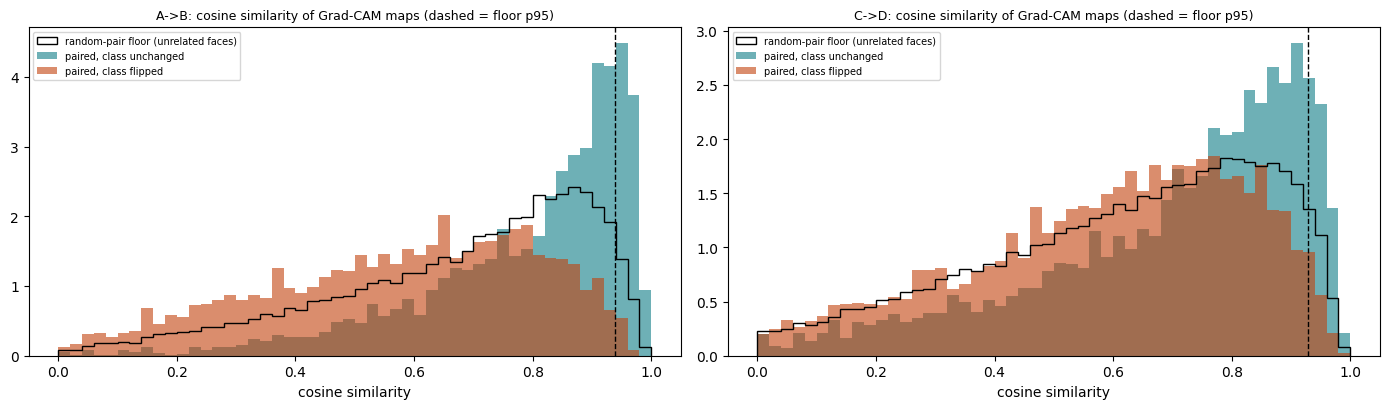

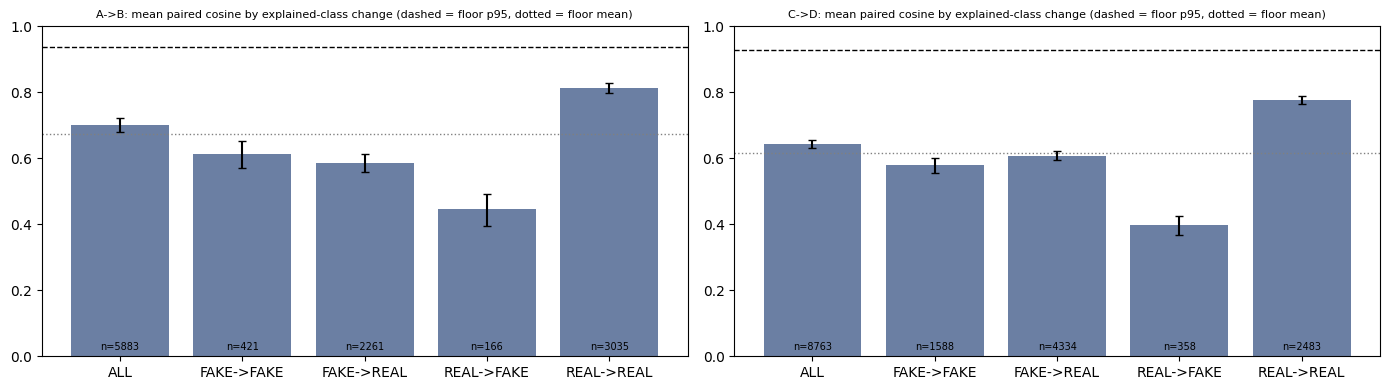

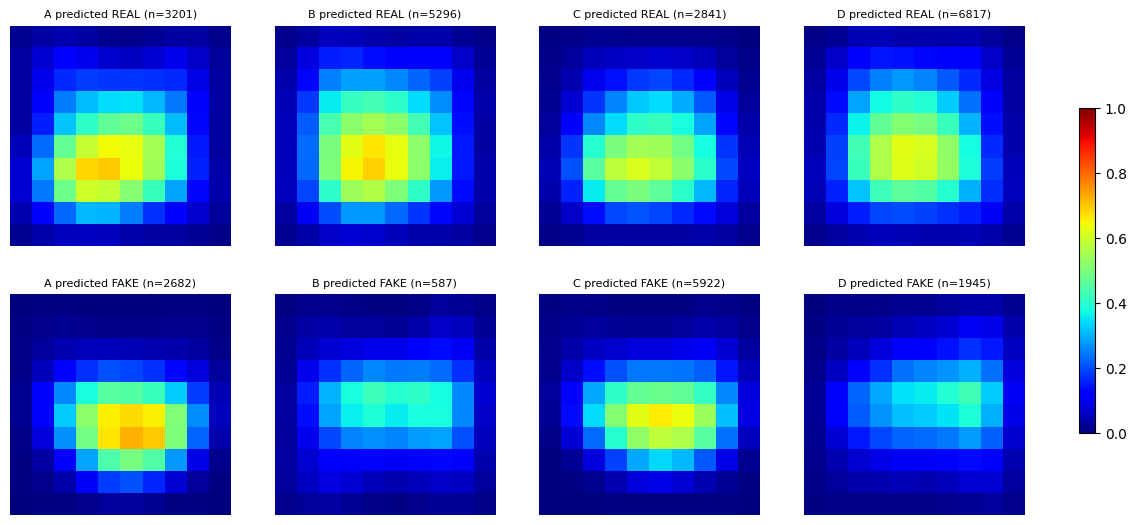

In [9]:
# ============================================================
# FIGURES
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, ((clean, comp), df) in zip(axes, paired.items()):
    pair = f"{clean}->{comp}"; bins = np.linspace(0, 1, 51)
    ax.hist(floors[pair]["within_clean"]["cos"][~np.isnan(floors[pair]["within_clean"]["cos"])], bins=bins, density=True, histtype="step", color="k", lw=1.5, label="random-pair floor (unrelated faces)")
    ax.hist(df.loc[~df["flip_target"], "cos"].dropna(), bins=bins, density=True, alpha=0.6, color="#0E7C86", label="paired, class unchanged")
    if df["flip_target"].any(): ax.hist(df.loc[df["flip_target"], "cos"].dropna(), bins=bins, density=True, alpha=0.6, color="#C2410C", label="paired, class flipped")
    ax.axvline(FLOOR[pair]["primary_p95"], color="k", ls="--", lw=1); ax.set_title(f"{pair}: cosine similarity of Grad-CAM maps (dashed = floor p95)", fontsize=9); ax.set_xlabel("cosine similarity"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "stability_hist_pairs.png"), dpi=130); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, pair in zip(axes, ("A->B", "C->D")):
    s = stab_summary[(stab_summary["pair"] == pair) & (stab_summary["group"].str.startswith("direction") | (stab_summary["group"] == "ALL"))]
    ax.bar(s["group"].str.replace("direction ", ""), s["cosine_mean"], yerr=[s["cosine_mean"] - s["cosine_ci_lo"], s["cosine_ci_hi"] - s["cosine_mean"]], capsize=3, color="#6B7FA3")
    ax.axhline(FLOOR[pair]["primary_p95"], color="k", ls="--", lw=1); ax.axhline(FLOOR[pair]["primary_mean"], color="gray", ls=":", lw=1)
    for i, n in enumerate(s["n_pairs"]): ax.text(i, 0.02, f"n={n}", ha="center", fontsize=7)
    ax.set_ylim(0, 1); ax.set_title(f"{pair}: mean paired cosine by explained-class change (dashed = floor p95, dotted = floor mean)", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "stability_by_group.png"), dpi=130); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(14, 6.4))
for r, (tg, tname) in enumerate(((-1, "predicted REAL"), (1, "predicted FAKE"))):
    for c, k in enumerate("ABCD"):
        X, d = subset(k, tg); im = axes[r, c].imshow(X.mean(0).reshape(GRID, GRID), cmap="jet", vmin=0, vmax=1)
        axes[r, c].set_title(f"{k} {tname} (n={len(d)})", fontsize=8); axes[r, c].axis("off")
fig.colorbar(im, ax=axes, fraction=0.015); plt.savefig(os.path.join(OUT, "mean_maps_by_target.png"), dpi=130, bbox_inches="tight"); plt.show()

In [10]:
# ============================================================
# CHECKS + METADATA
# ============================================================
checks = []
EXPECTED_FLIP = {"A->B": 0.4134, "C->D": 0.5347}      # Step 2.5 flip_summary (prediction flips)
for (clean, comp), df in paired.items():
    pair = f"{clean}->{comp}"; n_exp = len(cams[clean]["ids"])
    checks += [{"check": f"{pair}: one pair per clean face", "value": len(df), "limit": n_exp, "pass": len(df) == n_exp and df["pair_id"].is_unique},
               {"check": f"{pair}: twins share the video", "value": True, "limit": True, "pass": True},
               {"check": f"{pair}: cosine within [0,1]", "value": f"{df['cos'].min():.3f}..{df['cos'].max():.3f}", "limit": "0..1", "pass": bool(df["cos"].dropna().between(-1e-9, 1 + 1e-9).all())},
               {"check": f"{pair}: share of pairs with an empty map", "value": round(float(df['cos'].isna().mean()), 4), "limit": "informational", "pass": True},
               {"check": f"{pair}: Step 2.5 prediction-flip share matches flip_summary", "value": round(float(df['flip_2_5'].mean()), 4), "limit": f"{EXPECTED_FLIP[pair]} +/- 0.002", "pass": abs(float(df['flip_2_5'].mean()) - EXPECTED_FLIP[pair]) < 0.002},
               {"check": f"{pair}: paired mean cosine above floor mean (informational)", "value": f"{df['cos'].mean():.3f} vs {FLOOR[pair]['primary_mean']:.3f}", "limit": "informational", "pass": True}]
checks = pd.DataFrame(checks); checks.to_csv(os.path.join(OUT, "stability_checks.csv"), index=False); print(checks.to_string(index=False))
json.dump({"created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "model_sha256": g_meta["model_sha256"], "manifest_sha256": MANIFEST_SHA, "threshold": THRESHOLD,
           "primary_measure": "cosine similarity of normalised 10x10 maps", "cross_checks": ["pearson", f"top-{K_IOU}% cell IoU", "centre-of-mass shift"],
           "floors": {"primary": "random unrelated faces (different videos) within the clean condition", "also": ["within compressed", "clean vs compressed across videos"], "reps_per_face": FLOOR_REPS,
                      "p95_cosine": FLOOR},
           "direction_matched_floor": "stability_floor_direction_matched.csv (same explained-class combination, different video)", "flip_definition": "explained class (target from cams_*.npz) differs between clean face and compressed twin", "A_vs_C": "distribution level only, split-half reference",
           "bootstrap": f"{N_BOOT} resamples of videos (paired), {N_BOOT_DIST} (distribution)", "seed": SEED, "min_group": {"faces": MIN_FACES, "videos": MIN_VIDEOS}},
          open(os.path.join(OUT, "stability_meta.json"), "w"), indent=2)
print("\nsaved:", sorted(os.listdir(OUT)))
assert checks["pass"].all(), "AN INTEGRITY CHECK FAILED: do not start Step 2.9 until this is understood."
print("Done. Next: Step 2.9 outcome analysis. Do NOT retrain or change the threshold.")

                                                    check          value            limit  pass
                            A->B: one pair per clean face           5883             5883  True
                              A->B: twins share the video           True             True  True
                                A->B: cosine within [0,1]   0.002..0.997             0..1  True
                   A->B: share of pairs with an empty map            0.0    informational  True
A->B: Step 2.5 prediction-flip share matches flip_summary         0.4134 0.4134 +/- 0.002  True
A->B: paired mean cosine above floor mean (informational) 0.701 vs 0.673    informational  True
                            C->D: one pair per clean face           8763             8763  True
                              C->D: twins share the video           True             True  True
                                C->D: cosine within [0,1]   0.000..0.993             0..1  True
                   C->D: share of pairs 